In [ ]:
# importation des packages
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np
from tensorflow.keras.datasets import cifar10
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Activation, Flatten
from tensorflow.keras.layers import Conv2D, MaxPooling2D

In [ ]:
# chargement de la base de donnees
(x_train, y_train), (x_test, y_test) = cifar10.load_data()

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 1540s 9us/step


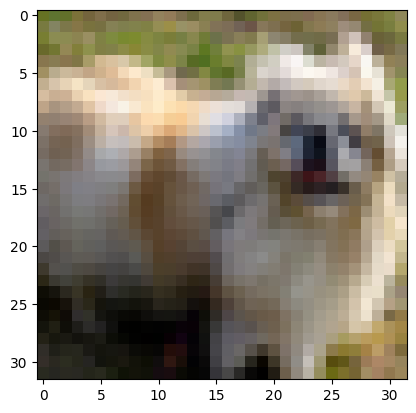

In [ ]:
plt.imshow(x_train[40])

array([[[100, 146, 192],
        [ 98, 144, 189],
        [ 99, 144, 189],
        ...,
        [165, 165, 165],
        [163, 163, 163],
        [165, 165, 165]],

       [[101, 145, 188],
        [100, 143, 186],
        [100, 143, 186],
        ...,
        [164, 161, 159],
        [163, 162, 159],
        [159, 161, 157]],

       [[105, 147, 189],
        [104, 145, 186],
        [104, 145, 187],
        ...,
        [156, 150, 147],
        [136, 133, 129],
        [114, 117, 111]],

       ...,

       [[166, 156, 150],
        [166, 156, 151],
        [168, 157, 152],
        ...,
        [137, 127, 112],
        [137, 126, 114],
        [147, 136, 127]],

       [[161, 152, 149],
        [162, 153, 150],
        [167, 158, 155],
        ...,
        [131, 125, 117],
        [138, 133, 124],
        [137, 132, 120]],

       [[164, 158, 155],
        [162, 156, 153],
        [164, 158, 155],
        ...,
        [153, 146, 139],
        [157, 151, 141],
        [156, 150, 137]]], dtype=uint8)
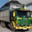

In [ ]:
x_train[14]

In [ ]:
# 255 c'est lintensite maximale pour un pixel d'image
# normalisation des donnees
x_train = x_train / 255
x_test = x_test / 255

In [ ]:
# Cree le modele
model = Sequential()

In [ ]:
# cree le reseau de convolution CNN
model.add(Conv2D(256, (3,3), input_shape=(32,32,3)))
model.add(Activation("relu"))
model.add(MaxPooling2D(pool_size=(2,2)))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
# ajoutons une autre couche de convolution
model.add(Conv2D(256, (3,3)))
model.add(Activation("relu"))
model.add(MaxPooling2D(pool_size=(2,2)))

In [ ]:
x_train.shape

(50000, 32, 32, 3)

In [ ]:
model.add(Flatten())

In [ ]:
# completement connecte (reseau de nourone)
model.add(Dense(128))
model.add(Dense(10))
model.add(Activation('sigmoid'))
model.compile(loss='sparse_categorical_crossentropy',optimizer="Adam",metrics=["sparse_categorical_crossentropy"])

In [ ]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 256)    │         7,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 30, 30, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 13, 13, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 13, 13, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 6, 6, 64)       │        16,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6, 6, 10)       │           650 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 6, 6, 10)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 360)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        46,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 64)             │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 668,810 (2.55 MB)

 Trainable params: 668,810 (2.55 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.fit(x_train, y_train, batch_size=32, epochs=10)

Epoch 1/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 17s 9ms/step - loss: 1.2967 - sparse_categorical_crossentropy: 1.2967
Epoch 2/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 12s 8ms/step - loss: 1.0153 - sparse_categorical_crossentropy: 1.0153
Epoch 3/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 13s 8ms/step - loss: 0.9340 - sparse_categorical_crossentropy: 0.9340
Epoch 4/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 13s 8ms/step - loss: 0.8762 - sparse_categorical_crossentropy: 0.8762
Epoch 5/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 12s 8ms/step - loss: 0.8372 - sparse_categorical_crossentropy: 0.8372
Epoch 6/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 12s 8ms/step - loss: 0.7990 - sparse_categorical_crossentropy: 0.7990
Epoch 7/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 12s 8ms/step - loss: 0.7705 - sparse_categorical_crossentropy: 0.7705
Epoch 8/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 12s 8ms/step - loss: 0.7385 - sparse_categorical_crossentropy: 0.7385
Epoch 9/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 12s 8ms/step - loss: 0.7140 - sparse_categorical_crossentropy:

In [ ]:
test_loss,test_accuracy = model.evaluate(x_test, y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.9299 - sparse_categorical_crossentropy: 0.9299
